In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.weightstats import ztest

In [2]:
df=pd.read_csv('India_Flood_Inventory_v3.csv')

In [3]:
df.head()

,Unnamed: 0,UEI,Start Date,End Date,Duration(Days),Main Cause,Location,Districts,State,Latitude,...,Human fatality,Human injured,Human Displaced,Animal Fatality,Description of Casualties/injured,Extent of damage,Event Source,Event Souce ID,District_LGD_Codes,State_Codes
0,563,UEI-IMD-FL-1967-0001,02-07-1967 00:00,08-07-1967 00:00,7.0,flood,NaN,NaN,Assam,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,18
1,564,UEI-IMD-FL-1967-0002,22-07-1967 00:00,28-07-1967 00:00,7.0,flood,NaN,NaN,"Maharashtra, Gujarat",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,"27,24"
2,565,UEI-IMD-FL-1967-0003,01-08-1967 00:00,30-08-1967 00:00,30.0,flood,NaN,NaN,Uttar Pradesh,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,9
3,566,UEI-IMD-FL-1967-0004,08-09-1967 00:00,09-09-1967 00:00,2.0,flood,NaN,"Bhadrak, Dhenkanal, Jajapur, Subarnapur, Nuapa...","Odisha, Bihar, Uttar Pradesh, Madhya Pradesh, ...",NaN,...,NaN,NaN,NaN,NaN,NaN,Marooning of Barwer Express,IMD,NaN,"348, 352, 356, None, 368, 345, 349, 350, 359, ...","21,10,9,23,8,6"
4,567,UEI-IMD-FL-1968-0001,22-06-1968 00:00,28-06-1968 00:00,7.0,flood,NaN,NaN,Assam,NaN,...,NaN,NaN,NaN,NaN,NaN,"Affecting about one million people,an area of ...",IMD,NaN,NaN,18


In [5]:
df.shape

(6876, 23)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6876 entries, 0 to 6875
Data columns (total 23 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         6876 non-null   int64  
 1   UEI                                6876 non-null   object 
 2   Start Date                         6856 non-null   object 
 3   End Date                           6856 non-null   object 
 4   Duration(Days)                     6857 non-null   float64
 5   Main Cause                         6845 non-null   object 
 6   Location                           0 non-null      float64
 7   Districts                          6817 non-null   object 
 8   State                              6876 non-null   object 
 9   Latitude                           0 non-null      float64
 10  Longitude                          0 non-null      float64
 11  Severity                           0 non-null      float

In [8]:
df.isnull().sum()

Unnamed: 0                              0
UEI                                     0
Start Date                             20
End Date                               20
Duration(Days)                         19
Main Cause                             31
Location                             6876
Districts                              59
State                                   0
Latitude                             6876
Longitude                            6876
Severity                             6876
Area Affected                        6876
Human fatality                       3106
Human injured                        5818
Human Displaced                      6754
Animal Fatality                      6305
Description of Casualties/injured    3609
Extent of damage                     3121
Event Source                            0
Event Souce ID                       6876
District_LGD_Codes                    304
State_Codes                           258
dtype: int64

In [9]:
df.duplicated().sum()

0

In [11]:
raw = pd.read_csv("India_Flood_Inventory_v3.csv")
print("Rows, columns:", raw.shape)
raw[["UEI", "Start Date", "End Date", "Duration(Days)", "Main Cause", "Districts", "State"]].head()

Rows, columns: (6876, 23)


,UEI,Start Date,End Date,Duration(Days),Main Cause,Districts,State
0,UEI-IMD-FL-1967-0001,02-07-1967 00:00,08-07-1967 00:00,7.0,flood,NaN,Assam
1,UEI-IMD-FL-1967-0002,22-07-1967 00:00,28-07-1967 00:00,7.0,flood,NaN,"Maharashtra, Gujarat"
2,UEI-IMD-FL-1967-0003,01-08-1967 00:00,30-08-1967 00:00,30.0,flood,NaN,Uttar Pradesh
3,UEI-IMD-FL-1967-0004,08-09-1967 00:00,09-09-1967 00:00,2.0,flood,"Bhadrak, Dhenkanal, Jajapur, Subarnapur, Nuapa...","Odisha, Bihar, Uttar Pradesh, Madhya Pradesh, ..."
4,UEI-IMD-FL-1968-0001,22-06-1968 00:00,28-06-1968 00:00,7.0,flood,NaN,Assam


In [12]:
df = raw.copy()

In [13]:
df.head()

,Unnamed: 0,UEI,Start Date,End Date,Duration(Days),Main Cause,Location,Districts,State,Latitude,...,Human fatality,Human injured,Human Displaced,Animal Fatality,Description of Casualties/injured,Extent of damage,Event Source,Event Souce ID,District_LGD_Codes,State_Codes
0,563,UEI-IMD-FL-1967-0001,02-07-1967 00:00,08-07-1967 00:00,7.0,flood,NaN,NaN,Assam,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,18
1,564,UEI-IMD-FL-1967-0002,22-07-1967 00:00,28-07-1967 00:00,7.0,flood,NaN,NaN,"Maharashtra, Gujarat",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,"27,24"
2,565,UEI-IMD-FL-1967-0003,01-08-1967 00:00,30-08-1967 00:00,30.0,flood,NaN,NaN,Uttar Pradesh,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,9
3,566,UEI-IMD-FL-1967-0004,08-09-1967 00:00,09-09-1967 00:00,2.0,flood,NaN,"Bhadrak, Dhenkanal, Jajapur, Subarnapur, Nuapa...","Odisha, Bihar, Uttar Pradesh, Madhya Pradesh, ...",NaN,...,NaN,NaN,NaN,NaN,NaN,Marooning of Barwer Express,IMD,NaN,"348, 352, 356, None, 368, 345, 349, 350, 359, ...","21,10,9,23,8,6"
4,567,UEI-IMD-FL-1968-0001,22-06-1968 00:00,28-06-1968 00:00,7.0,flood,NaN,NaN,Assam,NaN,...,NaN,NaN,NaN,NaN,NaN,"Affecting about one million people,an area of ...",IMD,NaN,NaN,18


In [14]:
df.columns = df.columns.str.strip()

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6876 entries, 0 to 6875
Data columns (total 23 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Unnamed: 0                         6876 non-null   int64  
 1   UEI                                6876 non-null   object 
 2   Start Date                         6856 non-null   object 
 3   End Date                           6856 non-null   object 
 4   Duration(Days)                     6857 non-null   float64
 5   Main Cause                         6845 non-null   object 
 6   Location                           0 non-null      float64
 7   Districts                          6817 non-null   object 
 8   State                              6876 non-null   object 
 9   Latitude                           0 non-null      float64
 10  Longitude                          0 non-null      float64
 11  Severity                           0 non-null      float

In [17]:
df["Start Date"] = pd.to_datetime(df["Start Date"], format="%d-%m-%Y %H:%M", errors="coerce")
df["End Date"]   = pd.to_datetime(df["End Date"],   format="%d-%m-%Y %H:%M", errors="coerce")
print( df["Start Date"].isna().sum())
df = df.dropna(subset=["Start Date"])  

0


In [18]:
df["Districts"] = df["Districts"].str.strip()
df["State"]     = df["State"].str.strip()

In [19]:
before = len(df)
df = df.drop_duplicates(subset=["Start Date", "Districts", "State"])
print( before - len(df))

74


In [20]:
def simplify_cause(text):
    text = str(text).lower()
    if "landslide" in text:
        return "Landslide"
    if "flash" in text:
        return "Flash flood"
    if "rain" in text:
        return "Heavy rain"
    if text == "nan":
        return "Unknown"
    return "Other"

In [21]:
df["Cause_Group"] = df["Main Cause"].apply(simplify_cause)

In [22]:
df["n_districts"] = df["Districts"].fillna("").apply(lambda s: len([d for d in s.split(",") if d.strip()]))

In [30]:
print("Rows :", len(df))
df["Cause_Group"].value_counts()

Rows : 6782


Cause_Group
Heavy rain     5096
Other           963
Flash flood     361
Landslide       331
Unknown          31
Name: count, dtype: int64

In [31]:
def get_city_events(name):
    has_city = df["Districts"].fillna("").str.contains(name, case=False, regex=False)
    is_local = df["n_districts"] <= MAX_DISTRICTS_PER_EVENT
    return df[has_city & is_local].copy()

In [37]:
CITY_NAME = "Mumbai"                       # city / district name to search for
FLOOD_FILE = "India_Flood_Inventory_v3.csv"
RAINFALL_FILE = "rainfall.csv"             # daily rainfall file (columns: date, rainfall_mm)
MAX_DISTRICTS_PER_EVENT = 5                # ignore huge multi-district reports (explained in Step 3)
COMPARE_CITIES = ["Mumbai", "Thane", "Pune", "Chennai", "Kolkata", "Delhi"]

In [38]:
all_mentions = df["Districts"].fillna("").str.contains(CITY_NAME, case=False, regex=False).sum()
city = get_city_events(CITY_NAME)

In [40]:
print(f"Reports mentioning {CITY_NAME} (any size): {all_mentions}")
print(f"Reports kept (<= {MAX_DISTRICTS_PER_EVENT} districts):  {len(city)}")
print("First event:", city['Start Date'].min().date(), "| Last event:", city['Start Date'].max().date())
city[["Start Date", "Duration(Days)", "Cause_Group", "Districts"]].tail()

Reports mentioning Mumbai (any size): 181
Reports kept (<= 5 districts):  156
First event: 1974-07-01 | Last event: 2023-07-20


,Start Date,Duration(Days),Cause_Group,Districts
6663,2023-06-28,1.0,Heavy rain,Mumbai Suburban
6666,2023-06-29,1.0,Heavy rain,Mumbai
6676,2023-07-19,1.0,Heavy rain,Mumbai
6682,2023-07-20,1.0,Heavy rain,Mumbai
6683,2023-07-20,1.0,Heavy rain,Mumbai Suburban


In [41]:
cols = ["Duration(Days)", "Human fatality", "Human injured", "Human Displaced", "Extent of damage", "Description of Casualties/injured"]
missing = pd.DataFrame({
    "missing_count": city[cols].isna().sum(),
    "missing_percent": (city[cols].isna().mean() * 100).round(1),
})
missing

,missing_count,missing_percent
Duration(Days),0,0.0
Human fatality,38,24.4
Human injured,86,55.1
Human Displaced,156,100.0
Extent of damage,55,35.3
Description of Casualties/injured,36,23.1


In [42]:
city["Duration(Days)"] = city["Duration(Days)"].fillna(1)

In [57]:
df = df.dropna(axis=1, how="all")
print(df.shape) 

(6782, 19)


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6782 entries, 0 to 6875
Data columns (total 19 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Unnamed: 0                         6782 non-null   int64         
 1   UEI                                6782 non-null   object        
 2   Start Date                         6782 non-null   datetime64[ns]
 3   End Date                           6782 non-null   datetime64[ns]
 4   Duration(Days)                     6782 non-null   float64       
 5   Main Cause                         6751 non-null   object        
 6   Districts                          6724 non-null   object        
 7   State                              6782 non-null   object        
 8   Human fatality                     3738 non-null   float64       
 9   Human injured                      1052 non-null   float64       
 10  Human Displaced                    113 no

In [61]:
original_dtypes = df.dtypes.copy()      
for col in df.columns:
    if df[col].isna().sum() == 0:
        continue                                       
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())     
    elif pd.api.types.is_datetime64_any_dtype(df[col]):
        df[col] = df[col].ffill().bfill()              
    else:
        mode = df[col].mode()
        df[col] = df[col].fillna(mode[0] if len(mode) else "Unknown")

In [63]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6782 entries, 0 to 6875
Data columns (total 19 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Unnamed: 0                         6782 non-null   int64         
 1   UEI                                6782 non-null   object        
 2   Start Date                         6782 non-null   datetime64[ns]
 3   End Date                           6782 non-null   datetime64[ns]
 4   Duration(Days)                     6782 non-null   float64       
 5   Main Cause                         6782 non-null   object        
 6   Districts                          6782 non-null   object        
 7   State                              6782 non-null   object        
 8   Human fatality                     6782 non-null   float64       
 9   Human injured                      6782 non-null   float64       
 10  Human Displaced                    6782 n

Text(0, 0.5, 'Number of reports')

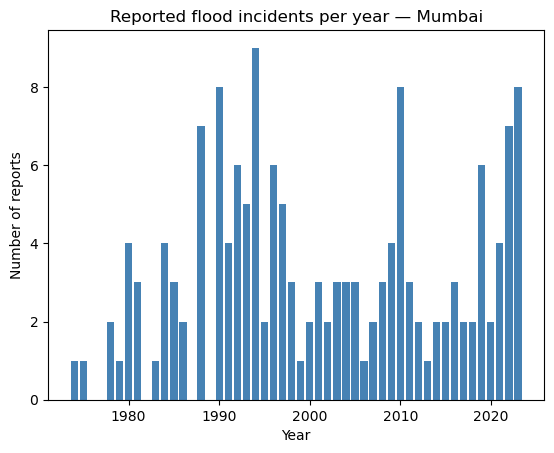

In [64]:
city["Year"]  = city["Start Date"].dt.year
city["Month"] = city["Start Date"].dt.month
per_year = city.groupby("Year").size()
per_year = per_year.reindex(range(per_year.index.min(), per_year.index.max() + 1), fill_value=0)  # years with 0 reports
plt.bar(per_year.index, per_year.values, color="steelblue")
plt.title(f"Reported flood incidents per year — {CITY_NAME}")
plt.xlabel("Year");
plt.ylabel("Number of reports")

Share of reports in Jun-Sep (monsoon): 93.6 %


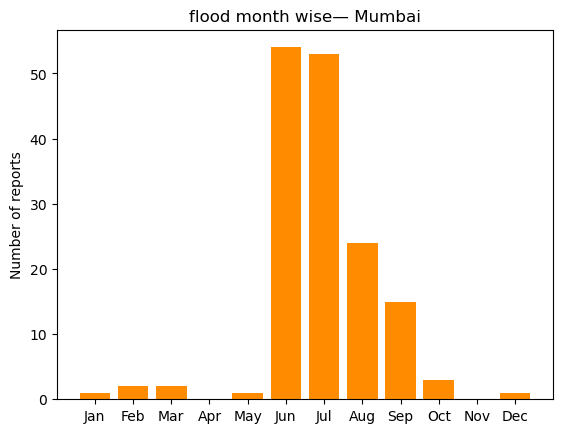

In [65]:
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
per_month = city.groupby("Month").size().reindex(range(1, 13), fill_value=0)
plt.bar(month_names, per_month.values, color="darkorange")
plt.title(f"flood month wise— {CITY_NAME}")
plt.ylabel("Number of reports")
print("Share of reports in Jun-Sep (monsoon):", round(per_month[[6,7,8,9]].sum() / per_month.sum() * 100, 1), "%")

Text(0, 0.5, 'Number of reports')

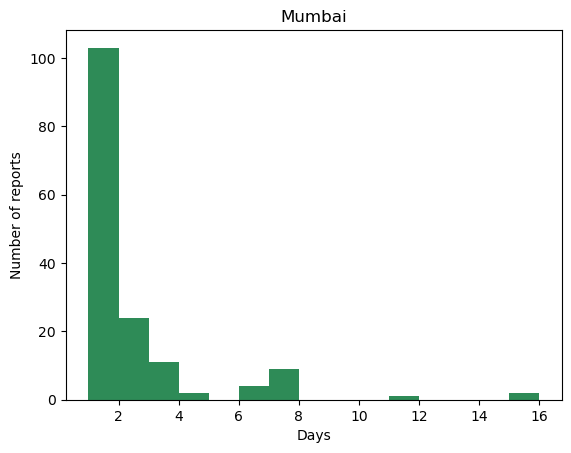

In [66]:
plt.hist(city["Duration(Days)"].clip(upper=15), bins=range(1, 17), color="seagreen")
plt.title(f"{CITY_NAME}")
plt.xlabel("Days");
plt.ylabel("Number of reports")

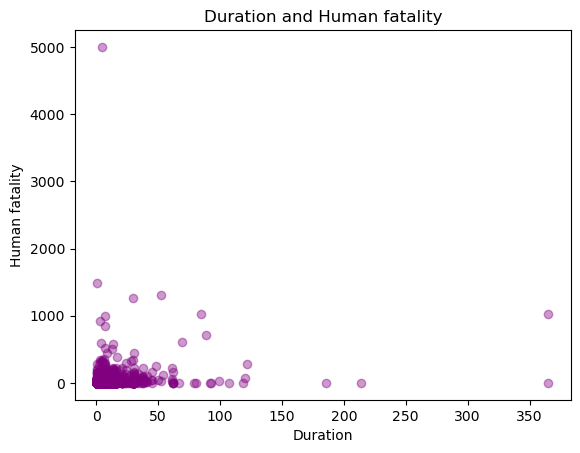

In [69]:
plt.scatter(df["Duration(Days)"], df["Human fatality" ], alpha=0.4, color="purple")
plt.xlabel("Duration"); plt.ylabel("Human fatality" ); plt.title(f"{"Duration"} and {"Human fatality" }");

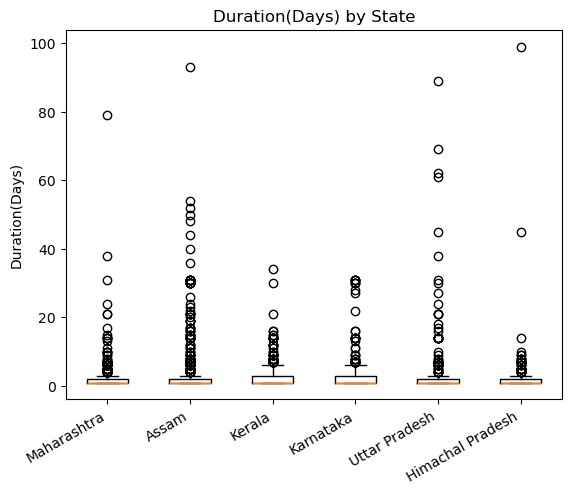

In [72]:
top = df["State"].value_counts().head(6).index
data = [df.loc[df["State"] == c, "Duration(Days)"].dropna() for c in top]
plt.boxplot(data); plt.xticks(range(1, len(top) + 1), top, rotation=30, ha="right")
plt.title(f"{"Duration(Days)"} by {"State"}"); plt.ylabel("Duration(Days)");

Text(0.5, 1.0, 'Flood duration by state')

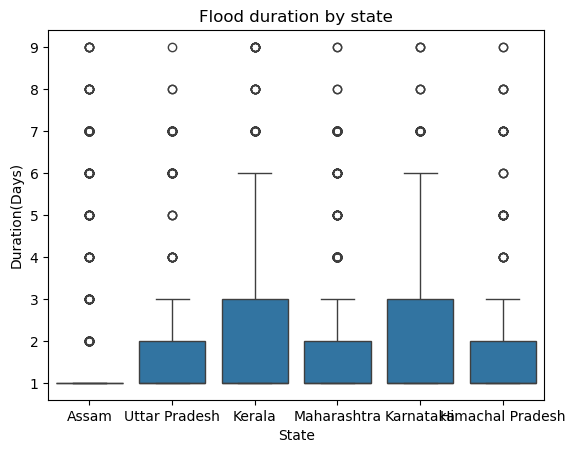

In [88]:
clean = df[(df["Duration(Days)"] > 0) & (df["Duration(Days)"] < 10)]
top_states = clean["State"].value_counts().head(6).index
clean = clean[clean["State"].isin(top_states)]
sns.boxplot(data=clean, x="State", y="Duration(Days)")
plt.title("Flood duration by state")

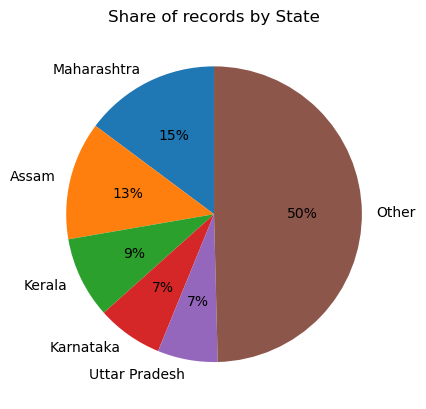

In [73]:
counts = df["State"].value_counts()
pie = pd.concat([counts.head(5), pd.Series({"Other": counts.iloc[5:].sum()})])
plt.pie(pie, labels=pie.index, autopct="%1.0f%%", startangle=90)
plt.title(f"Share of records by {"State"}");

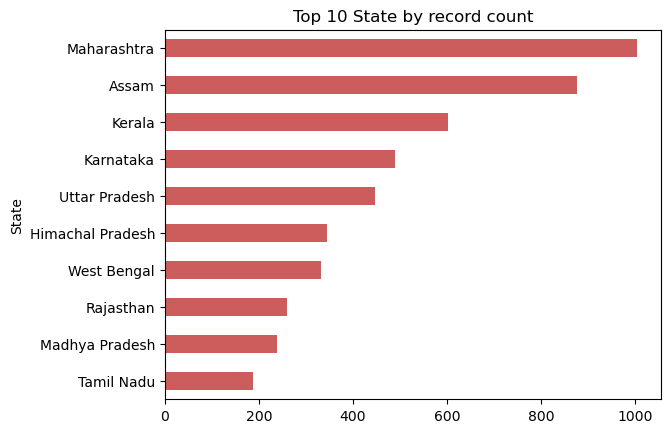

In [77]:
df["State" ].value_counts().head(10).sort_values().plot(kind="barh", color="indianred")
plt.title(f"Top 10 {"State" } by record count"); 